In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd

data = pd.read_csv("data_updated.csv")
data.head()

Saving data_updated.csv to data_updated.csv


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
#define X and y
X=data.drop("Target", axis=1)
y=data["Target"].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2})

/tmp/ipykernel_300/4067400173.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y=data["Target"].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2})


In [ ]:
binary_cols = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

numerical_cols = [
    col for col in X.columns
    if col not in binary_cols + categorical_cols
]

## **One-Hot Encoding**

In [ ]:

#do one hot encoding
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

X_train_pre, X_test_pre, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

encoder=OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded=encoder.fit_transform(X_train_pre[categorical_cols])
X_test_encoded=encoder.transform(X_test_pre[categorical_cols])


X_train_df=pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
X_test_df=pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))

X_train_pre = X_train_pre.reset_index(drop=True)
X_test_pre = X_test_pre.reset_index(drop=True)

X_train_en=pd.concat([X_train_pre.drop(categorical_cols, axis=1), X_train_df],axis=1)
X_test_en=pd.concat([X_test_pre.drop(categorical_cols, axis=1), X_test_df],axis=1)



In [ ]:
X_train_pre.shape

(3539, 36)

In [ ]:
X_train_en.shape

(3539, 244)

## **Balancing**

In [ ]:
#balancing
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

#undersampling
undersampler=RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_under_pre, y_under_pre=undersampler.fit_resample(X_train_pre,y_train)
X_under_en, y_under_en=undersampler.fit_resample(X_train_en,y_train)

#smote method
smote=SMOTE(sampling_strategy='auto', random_state=42)
X_smote_pre, y_smote_pre=smote.fit_resample(X_train_pre,y_train)
X_smote_en, y_smote_en=smote.fit_resample(X_train_en,y_train)

## **Scaling and Normalization**

In [ ]:
from sklearn.preprocessing import StandardScaler

#imbalanced data
scaler= StandardScaler() #scaling imbalanced (Original) data
X_train_ori=scaler.fit_transform(X_train_pre)
X_test_ori=scaler.transform(X_test_pre)

scaler_en= StandardScaler() #scaling imbalanced (encoded) data
X_train_enco=scaler_en.fit_transform(X_train_en)
X_test_enco=scaler_en.transform(X_test_en)

#undersampled data
scaler_under_ori= StandardScaler()
X_under_ori=scaler_under_ori.fit_transform(X_under_pre)
scaler_under_en= StandardScaler()
X_under_enco=scaler_under_en.fit_transform(X_under_en)

#smote data
scaler_smote_ori= StandardScaler()
X_smote_ori=scaler_smote_ori.fit_transform(X_smote_pre)
scaler_smote_en= StandardScaler()
X_smote_enco=scaler_smote_en.fit_transform(X_smote_en)


# **1) Naive Bayes**
##    **1.1 Gaussian Naive Bayes**

#### **Imbalanced dataset**

In [ ]:
#train the model using original features

from sklearn.naive_bayes import GaussianNB
nb_ori = GaussianNB()
nb_ori.fit(X_train_ori, y_train)

#predict class labels
y_pred_nb_ori = nb_ori.predict(X_test_ori)

In [ ]:
#train the model using encoded features

nb_enco = GaussianNB()
nb_enco.fit(X_train_enco, y_train)

#predict class labels
y_pred_nb_enco = nb_enco.predict(X_test_enco)

#### **Undersampled dataset**

In [ ]:
nb_under_ori = GaussianNB()
nb_under_ori.fit(X_under_ori, y_under_pre)

y_pred_nb_under_ori = nb_under_ori.predict(X_test_ori)

In [ ]:
nb_under_enco = GaussianNB()
nb_under_enco.fit(X_under_enco, y_under_en)

y_pred_nb_under_enco = nb_under_enco.predict(X_test_enco)

#### **SMOTE dataset**

In [ ]:
nb_smote_ori = GaussianNB()
nb_smote_ori.fit(X_smote_ori, y_smote_pre)

y_pred_nb_smote_ori = nb_smote_ori.predict(X_test_ori)

In [ ]:
nb_smote_enco = GaussianNB()
nb_smote_enco.fit(X_smote_enco, y_smote_en)

y_pred_nb_smote_enco = nb_smote_enco.predict(X_test_enco)

## **1.2 Bernoulli Nayve Bayes**

#### **Imbalanced dataset**

In [ ]:
#train the model using original features

from sklearn.naive_bayes import BernoulliNB
nb_ber_ori = BernoulliNB()
nb_ber_ori.fit(X_train_ori, y_train)

#predict class labels
y_pred_nb_ber_ori = nb_ber_ori.predict(X_test_ori)

In [ ]:
#train the model using encoded features

nb_ber_enco = BernoulliNB()
nb_ber_enco.fit(X_train_enco, y_train)

#predict class labels
y_pred_nb_ber_enco = nb_ber_enco.predict(X_test_enco)


#### **Underbalanced dataset**

In [ ]:
nb_ber_under_ori = BernoulliNB()
nb_ber_under_ori.fit(X_under_ori, y_under_pre)

y_pred_nb_ber_under_ori = nb_ber_under_ori.predict(X_test_ori)

In [ ]:
nb_ber_under_enco = BernoulliNB()
nb_ber_under_enco.fit(X_under_enco, y_under_en)

y_pred_nb_ber_under_enco = nb_ber_under_enco.predict(X_test_enco)

#### **SMOTE dataset**

In [ ]:
nb_ber_smote_ori = BernoulliNB()
nb_ber_smote_ori.fit(X_smote_ori, y_smote_pre)

y_pred_nb_ber_smote_ori = nb_ber_smote_ori.predict(X_test_ori)

In [ ]:
nb_ber_smote_enco = BernoulliNB()
nb_ber_smote_enco.fit(X_smote_enco, y_smote_en)

y_pred_nb_ber_smote_enco = nb_ber_smote_enco.predict(X_test_enco)

## **1.3 Evaluating Naive bayes**


### **1.3.1 Accuracy**

In [ ]:
from sklearn.metrics import accuracy_score

#Gaussian
print("Gaussian Naive Bayes - Imbalanced Original:", accuracy_score(y_test, y_pred_nb_ori))
print("Gaussian Naive Bayes - Imbalanced Encoded:", accuracy_score(y_test, y_pred_nb_enco))

print("Gaussian Naive Bayes - Undersample Original:", accuracy_score(y_test, y_pred_nb_under_ori))
print("Gaussian Naive Bayes - Undersample Encoded:", accuracy_score(y_test, y_pred_nb_under_enco))

print("Gaussian Naive Bayes - SMOTE Original:", accuracy_score(y_test, y_pred_nb_smote_ori))
print("Gaussian Naive Bayes - SMOTE Encoded:", accuracy_score(y_test, y_pred_nb_smote_enco))


#Bernoulli
print("\nBernoulli Naive Bayes - Imbalanced Original:", accuracy_score(y_test, y_pred_nb_ber_ori))
print("Bernoulli Naive Bayes - Imbalanced Encoded:", accuracy_score(y_test, y_pred_nb_ber_enco))

print("Bernoulli Naive Bayes - Undersample Original:", accuracy_score(y_test, y_pred_nb_ber_under_ori))
print("Bernoulli Naive Bayes - Undersample Encoded:", accuracy_score(y_test, y_pred_nb_ber_under_enco))

print("Bernoulli Naive Bayes - SMOTE Original:", accuracy_score(y_test, y_pred_nb_ber_smote_ori))
print("Bernoulli Naive Bayes - SMOTE Encoded:", accuracy_score(y_test, y_pred_nb_ber_smote_enco))

Gaussian Naive Bayes - Imbalanced Original: 0.6903954802259887
Gaussian Naive Bayes - Imbalanced Encoded: 0.23954802259887006
Gaussian Naive Bayes - Undersample Original: 0.6463276836158192
Gaussian Naive Bayes - Undersample Encoded: 0.5073446327683616
Gaussian Naive Bayes - SMOTE Original: 0.5819209039548022
Gaussian Naive Bayes - SMOTE Encoded: 0.19548022598870057

Bernoulli Naive Bayes - Imbalanced Original: 0.7254237288135593
Bernoulli Naive Bayes - Imbalanced Encoded: 0.7084745762711865
Bernoulli Naive Bayes - Undersample Original: 0.6983050847457627
Bernoulli Naive Bayes - Undersample Encoded: 0.6689265536723163
Bernoulli Naive Bayes - SMOTE Original: 0.7016949152542373
Bernoulli Naive Bayes - SMOTE Encoded: 0.6836158192090396


##### 1. gaussian naive bayes performed well on the original feature space cuz they were (continuous/numerical). This gave a better accuracy because gaussian nb normally assumes that each feature follows a normal/bell-shaped/gaussian distribution. however, its important to keep in mind that some of the numerical features were categorical, so results using gaussian may not be accurate

##### 2. what happened here is that when we applied the one-hot encoding, values of features became 0 or 1. This violated the gaussian nb's assumption, cuz the values are binary so there is no bell curve possible (That's why i searched for another naive bayes type that can handle binary features and the result was.. BERNOULLI NB)

##### 3. after undersampling, the accuracy decreased slightly to 64.6%. Undersampling balances dataset by removing smaples from the majority class but this also reduces the amount of available training data, therefore the model might lose some info which leades to a decrease in performance.

##### 4. now when undersampling was applied to an encoded dataset, the accuracy increased to 50.7% compared to imbalanced encoded case! I believe this is bcz balancing reduces the dominance of the majority class (in the imbalanced version, the model may have tendency to favor the graduate class even if our model didnt show strong signs of bias, but still there could be some influence. when the data was balanced, each class has equal prior probability, which removes the dominance of the majority class and forces the model to learn patterns for all classes more equally. This then can leade to improved predictions). Anyway it not a high score since the gaussian assumption is still violated.



##### 5. using somte on original dataset resulte din an accuracy of 58.1%. Smote generates synthetic samples for the minority classes in order to balance the dataset. now although this helps increase the representation of minority classes, the synthetic points may slightly alter the natural distribution of the features and because gaussian relies on assumptions about feature distributions, this small distortion can sometimes reduce the model's accuracy.


##### 6. using smote on encoded dataset resulte in an accuracy of 19.5%. this is similar to the encoded imbalanced dataset, gaussian behaves poorly with binary features and the addition of synthetic data from smote further increases variability, making it even harder for the model to learn effectively.


##### 7. bernoulli resulted in the highest acuracy score of 72.5% ont he original imbalanced dataset Bernoulli was noticeably performing better than Gaussian cuz its designed for binary features and is much better suited for one-hot encoding data. another thing to notice is that bernoulli was able to capture meaningful patterns in data even without balancing it

##### 8. the encoding slightly reduced the bernoulli performance to 70.8 % cuz one-hot encoding added noise, increased the dimensionality, and added more redundancy i guess. BUT it's still high which means its stable

##### 9. again, same thing, when undersampling was applied to the original dataset, the accuracy decreased slightly to 69.8%, this bcz while undersampling balances data, it removes a portion of the majority class data which may reduce the amout of info available for the model to learn from

##### 10. undersampling-encoded resulted in an accuracy of 66.9%. Now there are 2 main reasons why it behaved slightly worse than undersampled original. first is because after one-hot encoding, the dimensionality increased significantly, adding some noise and redundancy. second, undersampling made this worse by removing portion of data that the model couldve learned from  

##### 11. applying smote on original dataset resulted in an accuracy of 70.2%. this is noticeably high! now we know that smote increases the num of minority class samples by generating synthetic data points which helps balancing the dataset. However the accuracy of this version was very close to the accuracy on the original imbalanced dataset. this suggests that class imbalance was not a major issue in this dataset since the model was already able to learn patterns from all classes without requiring balancing. important thing to highlight is that this version performed better than gaussian-original-smote dataset bcz our dataset originally included some binary features which dragged the perfomance of gaussian down compared to bernoulli!

##### 12. smote-encoded version's accuracy was 68.4%. Again the slight decrease comes from the noise and redundancy after applying one-hot encoding. the reason it behaved worse than imbalanced encoded version is bcz it introduced synthetic data points that werent real observations and may have added some noise

#### **based on these results, for now, i can say that using bernoulli on the imbalanced original dataset gave the best accuracy result, however, since our dataset clearly needs encoding due to the numerical-categorical features, bernoulli nb on encoded dataset is what i believe we can rely on as it provides stable results**

#### **Another thing to highlight: the reason why bernoulli behaved good in the original datasets in general is bcz the data was normalized and bernoulli internally converts standardised values to binary using zero as a threshold**

#### **Since the data is still (imbalanced), accuracy cannot be trusted alone as a measurement, cuz it doesnt tell us how the classes were predicted and it might predict the (Graduate) class well but ignore the smallest class (Enrolled)**

##### so i wanted to compare my results to the baseline accuracy

In [ ]:
#baseline accuracy: ~0.5
# it represents accuracy of a very naive model that always predicts the majority class (graduate).
#this indicates that the model is not dumb (only being correct when the true lablel is Graduate)
#That applies to the all cases tested above
# it suggests that the model is capable of generating meaningful predictions

class_counts=y.value_counts()
print("Class Distribution:\n", class_counts)

majority=class_counts.max()
total=len(y)

baseline_acc=majority/total
print("\nThe baseline accuracy of (majority Class) is: ", baseline_acc)

Class Distribution:
 Target
0    2209
1    1421
2     794
Name: count, dtype: int64

The baseline accuracy of (majority Class) is:  0.4993218806509946


### **1.3.2 Classification Report**

In [ ]:
from sklearn.metrics import classification_report
#original - imbalanced (gaussian)

print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ori))

#the model handles Graduate very well (it correctly identifies 82% of real graduates and the predictions of graduates are correct 75% of the time), it is correct 75% of the time), Dropout reasoably well, but it almost fails on Enrolled
#so although the accuracy looks good, the models is clearly biased toward larger classes
#moderate model, not balanced, and is weak on smaller classes

Classification Report:

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       442
           1       0.72      0.73      0.72       284
           2       0.37      0.26      0.31       159

    accuracy                           0.69       885
   macro avg       0.61      0.60      0.60       885
weighted avg       0.67      0.69      0.68       885



In [ ]:
#encoded - imbalanced (gaussian)

print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_enco))

#the model is basically horrible
#graduate recall =0.01 (the model almost never predicts the graduate class correctly) and enrolled recall =0.94(the model predicts this class almost all the time)  which indiactes overpredicting this class
#the model is strongly biased towards the enrolled class which causes the overall accuracy to drop to 24 which is even below the baseline accuracy
#clearly failed model that is not usable

Classification Report:

              precision    recall  f1-score   support

           0       0.60      0.01      0.03       442
           1       0.59      0.20      0.30       284
           2       0.19      0.94      0.32       159

    accuracy                           0.24       885
   macro avg       0.46      0.38      0.21       885
weighted avg       0.52      0.24      0.17       885



In [ ]:
#original - undersampled (gaussian)

print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_under_ori))

#Moderate model, slightly more balanced than before, performs well on Graduate and Dropout, but still weak on the smallest class (Enrolled).
#graduate (good performance), dropout(also good), enrolled (weak but better than before)
#Undersampling helped the model reduce the dominance of the majority class, which slightly improved balance, but the model still struggles with the smallest class.

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.67      0.73       442
           1       0.72      0.74      0.73       284
           2       0.29      0.41      0.34       159

    accuracy                           0.65       885
   macro avg       0.60      0.61      0.60       885
weighted avg       0.68      0.65      0.66       885



In [ ]:
#encoded - undersampled (gaussian)

print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_under_enco))

#the model is also horrible
#enrolled recall =0.01 (the model almost never predicts the enrolled class correctly) and graduate recall =0.97(the model predicts this class almost all the time)  which indiactes overpredicting this class, dropout is ignored
#the model strongly favors the Graduate class, which leads to very weak performance on the other classes.
#poor and unbalanced model, heavily biased toward the Graduate class and unable to correctly detect the smaller classes.

Classification Report:

              precision    recall  f1-score   support

           0       0.51      0.97      0.67       442
           1       0.60      0.06      0.11       284
           2       0.20      0.01      0.02       159

    accuracy                           0.51       885
   macro avg       0.44      0.35      0.27       885
weighted avg       0.48      0.51      0.37       885



In [ ]:
#original - smote (gaussian)

print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_smote_ori))

#graduate (moderate performance), dropouts (good performance), enrolled(weak but the recall mproved compared to the imbalanced and underbalanced)
#Smote helped the model detect more Enrolled students, which increased its recall, but overall performance remains moderate and still not fully balanced.
#Moderate model, slightly more balanced than the imbalanced case, performs well on Dropout, reasonably on Graduate, but still weak on the smallest class (Enrolled).

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.51      0.62       442
           1       0.72      0.73      0.73       284
           2       0.26      0.53      0.35       159

    accuracy                           0.58       885
   macro avg       0.60      0.59      0.57       885
weighted avg       0.68      0.58      0.61       885



In [ ]:
#encoded - smote (gaussian)

print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_smote_enco))

#Very poor model, highly unbalanced, strongly biased toward the Enrolled class, and fails to correctly predict Graduate and Dropout.
#graduate and dropout (almost never predicted correctly, indicating extremely poor detection), enrolled(its predicted almost all the time)
#the model is strongly biased towards the enrolled class which causes the overall accuracy to drop to 20
#worst so far

Classification Report:

              precision    recall  f1-score   support

           0       0.38      0.03      0.05       442
           1       0.50      0.04      0.07       284
           2       0.18      0.94      0.30       159

    accuracy                           0.20       885
   macro avg       0.35      0.34      0.14       885
weighted avg       0.38      0.20      0.10       885



In [ ]:
#original - imbalanced (bernoulli)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ber_ori))

#this model is relatively balanced, although the Enrolled class is still weak but its detected
#so far, its the best performing model, relatively balanced and stable

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.84      0.82       442
           1       0.74      0.78      0.76       284
           2       0.42      0.30      0.35       159

    accuracy                           0.73       885
   macro avg       0.65      0.64      0.64       885
weighted avg       0.71      0.73      0.71       885



In [ ]:
#encoded - imbalanced (bernoulli)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ber_enco))

#this is very similar to the original Bernoulli
#there is a slight drop in accuracy (from 73 to 71) but macro f1 remains unchanged
#performs moderately on enrolled (f1 is better than the previous models)
#almost identical to the original bernoulli, thus good and stable

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.79      0.80       442
           1       0.71      0.77      0.74       284
           2       0.41      0.37      0.39       159

    accuracy                           0.71       885
   macro avg       0.64      0.64      0.64       885
weighted avg       0.70      0.71      0.71       885



In [ ]:
#original - undersampled (bernoulli)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ber_under_ori))

#Good and fairly balanced model, performs well on Graduate and Dropout and reasonably on the smallest class (Enrolled), with stable overall performance.
#Enrolled f1 score: better than most previous models
#slightly reduced accuracy (0.70) compared to the original Bernoulli model, but it improved the detection of the smallest class (Enrolled).

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.75      0.78       442
           1       0.76      0.75      0.75       284
           2       0.37      0.45      0.41       159

    accuracy                           0.70       885
   macro avg       0.65      0.65      0.65       885
weighted avg       0.72      0.70      0.71       885



In [ ]:
#encoded - undersampled (bernoulli)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ber_under_enco))

#Moderate-to-good model, fairly balanced, performs well on Graduate and Dropout and moderately on the smallest class (Enrolled).
#accuracy dropped slightly (0.67), but the model still maintains reasonable balance across classes.

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.70      0.76       442
           1       0.70      0.74      0.72       284
           2       0.34      0.45      0.39       159

    accuracy                           0.67       885
   macro avg       0.62      0.63      0.62       885
weighted avg       0.70      0.67      0.68       885



In [ ]:
#original - smote (bernoulli)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ber_smote_ori))

#Good and fairly balanced model, performs strongly on Graduate and Dropout and moderately on the smallest class (Enrolled).

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.76      0.79       442
           1       0.76      0.76      0.76       284
           2       0.37      0.43      0.39       159

    accuracy                           0.70       885
   macro avg       0.65      0.65      0.65       885
weighted avg       0.72      0.70      0.71       885



In [ ]:
#encoded - smote (bernoulli)
print("Classification Report:\n")
print(classification_report(y_test, y_pred_nb_ber_smote_enco))

#Good and fairly balanced model, performs well on Graduate and Dropout and moderately on the smallest class (Enrolled), but with slightly lower overall accuracy.

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.74      0.78       442
           1       0.69      0.76      0.72       284
           2       0.36      0.40      0.38       159

    accuracy                           0.68       885
   macro avg       0.62      0.63      0.63       885
weighted avg       0.70      0.68      0.69       885



### **1.3.3 Confusion Matrix**

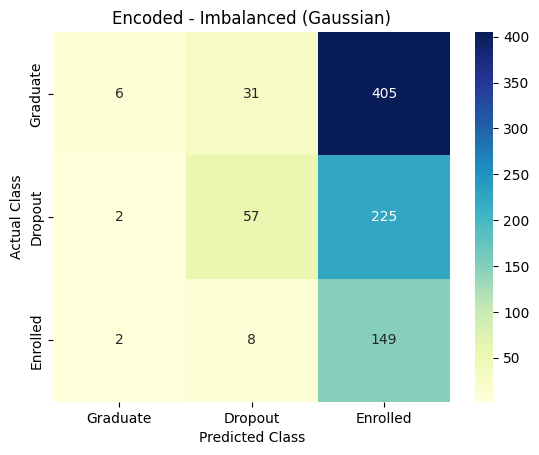

In [ ]:
#encoded - imbalanced (gaussian)
import matplotlib.pyplot as plt # for data visualization
import seaborn as sns # for statistical data visualization
from sklearn.metrics import confusion_matrix

class_names = ['Graduate', 'Dropout', 'Enrolled']

cm = confusion_matrix(y_test, y_pred_nb_enco)

cm_matrix = pd.DataFrame(cm, columns=class_names, index=class_names)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Encoded - Imbalanced (Gaussian)")
plt.show()

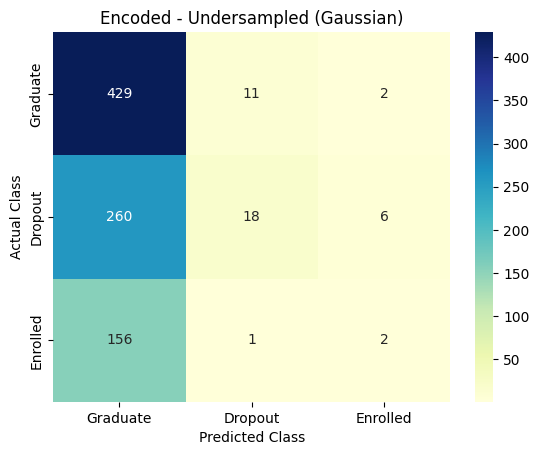

In [ ]:
#encoded - undersampled (gaussian)
cm = confusion_matrix(y_test, y_pred_nb_under_enco)

cm_matrix = pd.DataFrame(cm, columns=class_names, index=class_names)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Encoded - Undersampled (Gaussian)")
plt.show()

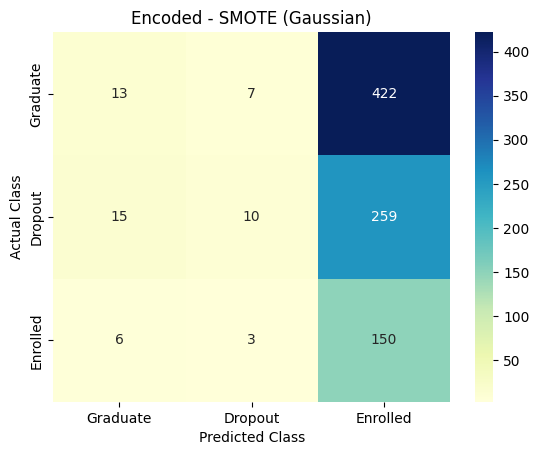

In [ ]:
#encoded - smote (gaussian)
cm = confusion_matrix(y_test, y_pred_nb_smote_enco)

cm_matrix = pd.DataFrame(cm, columns=class_names, index=class_names)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Encoded - SMOTE (Gaussian)")
plt.show()

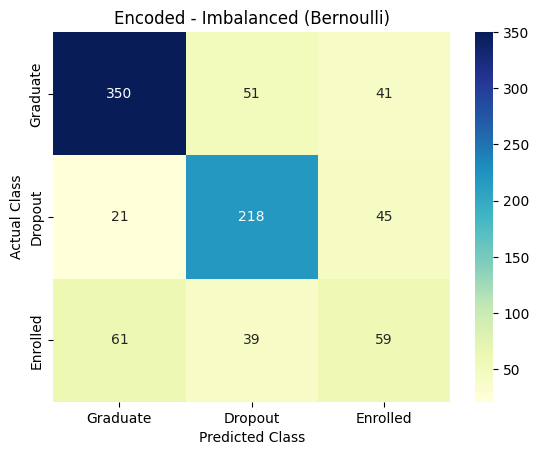

In [ ]:
import matplotlib.pyplot as plt # for data visualization
import seaborn as sns # for statistical data visualization
from sklearn.metrics import confusion_matrix

#Encoded - imbalanced (bernoulli)
class_names = ['Graduate', 'Dropout', 'Enrolled']

cm = confusion_matrix(y_test, y_pred_nb_ber_enco)

cm_matrix = pd.DataFrame(cm, columns=class_names, index=class_names)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Encoded - Imbalanced (Bernoulli)")
plt.show()

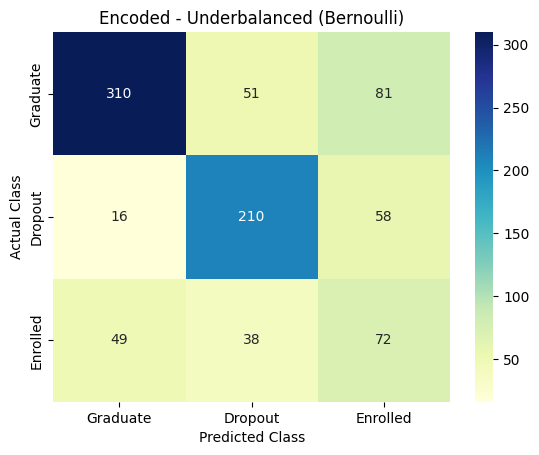

In [ ]:
#Encoded - Undersampled (bernoulli)
cm = confusion_matrix(y_test, y_pred_nb_ber_under_enco)

cm_matrix = pd.DataFrame(cm, columns=class_names, index=class_names)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Encoded - Underbalanced (Bernoulli)")
plt.show()

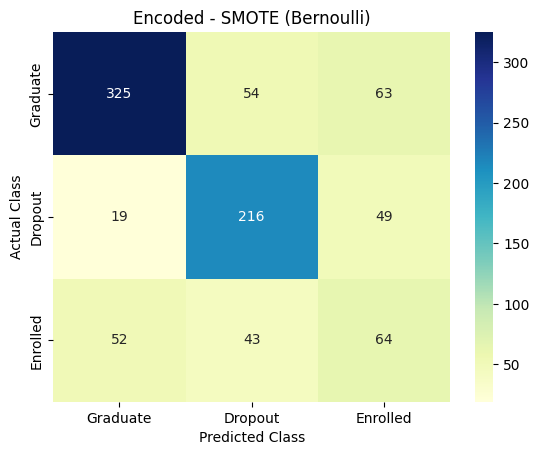

In [ ]:
#Encoded - SMOTE (bernoulli)
cm = confusion_matrix(y_test, y_pred_nb_ber_smote_enco)

cm_matrix = pd.DataFrame(cm, columns=class_names, index=class_names)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Encoded - SMOTE (Bernoulli)")
plt.show()

### **1.3.4 Macro Average Precision**
##### measures the average precision for all classes, treating them equally

In [ ]:
# encoded - imbalanced (gaussian)
from sklearn.metrics import precision_score
print("\nMacro Average Precision:", precision_score(y_test, y_pred_nb_enco, average='macro'))


Macro Average Precision: 0.46167362002567397


In [ ]:
# encoded - undersampled (gaussian)

print("\nMacro Average Precision:", precision_score(y_test, y_pred_nb_under_enco, average='macro'))


Macro Average Precision: 0.4358974358974359


In [ ]:
# encoded - smote (gaussian)

print("\nMacro Average Precision:", precision_score(y_test, y_pred_nb_smote_enco, average='macro'))


Macro Average Precision: 0.3542861187796418


In [ ]:
# encoded - imbalanced (bernoulli)

from sklearn.metrics import precision_score
print("\nMacro Average Precision:", precision_score(y_test, y_pred_nb_ber_enco, average='macro'))


Macro Average Precision: 0.6416246482338436


In [ ]:
# encoded - undersampled (bernoulli)

print("\nMacro Average Precision:", precision_score(y_test, y_pred_nb_ber_under_enco, average='macro'))


Macro Average Precision: 0.6234133437595214


In [ ]:
# encoded - smote (bernoulli)

print("\nMacro Average Precision:", precision_score(y_test, y_pred_nb_ber_smote_enco, average='macro'))


Macro Average Precision: 0.6248130936629339


### **1.3.5 Macro Average Recall**

In [ ]:
#encoded - imbalanced (gaussian)
from sklearn.metrics import recall_score
print("\nMacro Average Recall:", recall_score(y_test, y_pred_nb_enco, average='macro'))


Macro Average Recall: 0.3837952680748635


In [ ]:
#encoded - undersampled (gaussian)

print("\nMacro Average Recall:", recall_score(y_test, y_pred_nb_under_enco, average='macro'))


Macro Average Recall: 0.3488490444454866


In [ ]:
#encoded - smote (gaussian)

print("\nMacro Average Recall:", recall_score(y_test, y_pred_nb_smote_enco, average='macro'))


Macro Average Recall: 0.33600641957553684


In [ ]:
#encoded - imbalanced (bernoulli)
from sklearn.metrics import recall_score
print("\nMacro Average Recall:", recall_score(y_test, y_pred_nb_ber_enco, average='macro'))


Macro Average Recall: 0.6435100066042211


In [ ]:
#encoded - undersampled (bernoulli)

print("\nMacro Average Recall:", recall_score(y_test, y_pred_nb_ber_under_enco, average='macro'))


Macro Average Recall: 0.6312080914869678


In [ ]:
#encoded - smote (bernoulli)

print("\nMacro Average Recall:", recall_score(y_test, y_pred_nb_ber_smote_enco, average='macro'))


Macro Average Recall: 0.632791073733063


### **1.3.6 F1 - Score**
##### it balances the precision and recall and treats classes equally. Technically its the most reliable metric for imbalanced multi class data

In [ ]:
#encoded  - imabalanced (gaussian)
#very poor balance, its mostly predicting one class (enrolled)

from sklearn.metrics import f1_score

print("\nMacro F1:", f1_score(y_test, y_pred_nb_enco, average='macro'))


Macro F1: 0.21474863357045368


In [ ]:
#encoded  - undersampled (gaussian)

print("\nMacro F1:", f1_score(y_test, y_pred_nb_under_enco, average='macro'))


Macro F1: 0.26832832908286114


In [ ]:
#encoded  - smote (gaussian)

print("\nMacro F1:", f1_score(y_test, y_pred_nb_smote_enco, average='macro'))


Macro F1: 0.1411472084846698


In [ ]:
#encoded - imbalanced (bernoulli)
from sklearn.metrics import f1_score
print("\nMacro F1:", f1_score(y_test, y_pred_nb_ber_enco, average='macro'))


Macro F1: 0.6418532376770363


In [ ]:
#encoded - undersampled (bernoulli)

print("\nMacro F1:", f1_score(y_test, y_pred_nb_ber_under_enco, average='macro'))


Macro F1: 0.6228249273352158


In [ ]:
#encoded - smote (bernoulli)

print("\nMacro F1:", f1_score(y_test, y_pred_nb_ber_smote_enco, average='macro'))


Macro F1: 0.6271213224244687


### **Therefore, Bernoulli Naive Bayes is the most appropriate model for this dataset.**

## Just to mention that bernoulli worked well on original features bcz:

### *   **our original dataset contains many binary features**
### *   **bernoulli internally converts standardised values to binary using zero as a threshold (so like x>0 =1 and x<=0 =0)**


# **2) K-Means**

### **Before PCA**

### **2.1 Elbow method (Choosing K)**
#### **After Encoding**


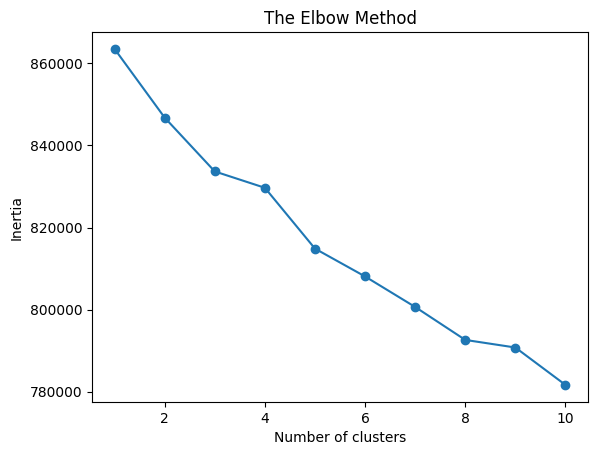

In [ ]:
# the elbow appears around k=5, this where the rate of inertia reduction slows

from sklearn.cluster import KMeans

inertia = []
for i in range(1, 11):
    kmeans_temp = KMeans(n_clusters = i, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
    kmeans_temp.fit(X_train_enco)
    inertia.append(kmeans_temp.inertia_)
plt.plot(range(1, 11), inertia, marker="o")
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

## **2.2 training k-means**

In [ ]:

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_train_enco)

clusters = kmeans.predict(X_train_enco)  #clusters assignment step


## **2.3 Cluster Evaluation**

### **Silhouette Score**

####   The following is to evaluate the clusters and how well separated are they

In [ ]:
from sklearn.metrics import silhouette_score

s_score = silhouette_score(X_train_enco, clusters)
print("The Silhouette Score:", s_score)

#n_clusters=5 gave asilhouette score of 0.0071 which means the clusters are overlapping heavily and arent well separated (almost no separation between clusters and k-means is struggling to find distinct group structure)
#n_clusters=3 gave asilhouette score of 0.0953 indicating slightly better separation
#n_clusters=4 gave asilhouette score of 0.0959 indicating even better better separation
#n_clusters=2 gave asilhouette score of 0.1056 which is the highest, indicating that 2 clusters produce the best geometric separation in the dataset
#(however its still very low which indicates that clusters overlap heavily and the dataset doesnt have strong natural cluster boundaries)
#although there are 3 true labels but the natural structure is 2 clusters
#then there should be 2 classes that are geometrically similar

#reason why the values were very low after one-hot encoding is because of the very high dimensional spaces
#this causes many poitns to become equally distant, clusters are harder to separate, and the distance differences become very small which weakens the geometric separation between clusters


The Silhouette Score: 0.09529030218689


### **Adjusted Rand Index**
#### measures how accurate a clustering result is by comparing it to the true labels (ground truth).

In [ ]:
from sklearn.metrics import adjusted_rand_score

ad_rand = adjusted_rand_score(y_train, clusters)

print("Adjusted Rand Index: ", ad_rand)

 #very important note:

 #although setting k=2 produced the highest silhouette score of ~0.1056, which indicated a better geometric separation
 #BUT, the adjusted random index value of (~ -0.055) suggests that clustering with 2 clusters doesn't align with the true class labels well

  #k=5 produced much lower silhouette score of 0.007 and the ari value was (0.14)

 #On the other hand, setting k=3 produced a slightly lower silhouette score of (~0.0953) which indicated weaker geometric separation(maybe cuz the classes were originally overlapping)
 #HOWEVER, the adjusted random index value of (~0.1538) suggests that even if the value isn't strong, k=3 aligns better with the true labels

 #k=4 gave a silhouette score of 0.0959 and an ari score of 0.1542
 #This actually gives the best score amongst all!! (might suggest that k-means splitted one class into 2 subgroups)

Adjusted Rand Index:  0.15377199181684645


### **cross-tabulation matrix**
#### showcasing the distribution of data points across the clusters

In [ ]:
clust_dist = pd.crosstab(clusters, y_train)
print(clust_dist)

#when k=2, clusters contained heavy mix of the 3 classes. cluster 0 was dominated by dropouts and cluster 1 was dominated by graduate but many other samples were present there and enrolled students are scattered in both clusters

#for k=3, cluster 0 was mainly graduate, cluster 2 was mostly dropouts, cluster 1 was large and mixed(mostly graduate but also contains many enrolled and dropouts (so its mixed but dominated by graduate)
#so there is some structure but one cluster (C2) mixes everything, this further supports the fact that (k=3 is weak but not random)

#for k=4, cluster 3 has only 1 data point which means that it created a useless cluster (not meaningful)
#its like it isolated one extreme outlier in another cluster

#k=5 did also the same as k=4 (isolated one data point in a separate cluster) + cluster 2 was tiny. In general, its as if it split the graduate group into multiple sub groups

#verdict: although k=4 produced the highest silhouette score, it generated a useless cluster
#since k=3 produced nearly identical ari while maintaining a better separation, i would say k=3 should be the final num of clusters

Target     0    1    2
row_0                 
0        307  184   88
1       1400  407  490
2         60  546   57


### **Therefore, k=3 is the best choice**

### **Cluster Visualization**
#### 2D PCA with centroids

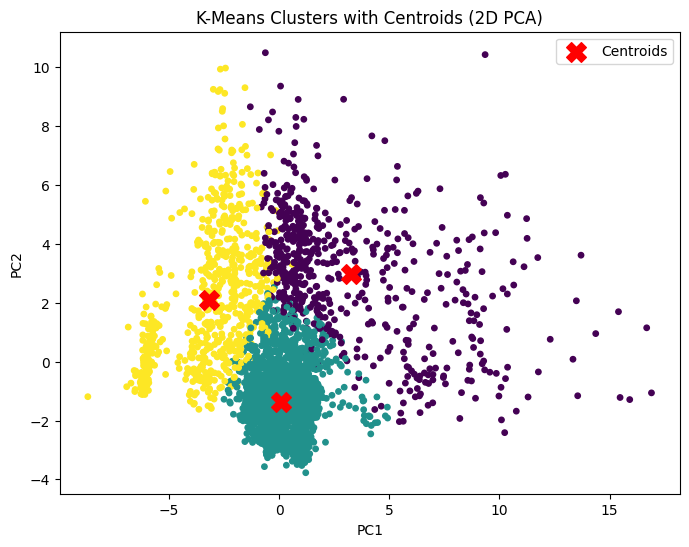

In [ ]:
# Project centroids into PCA space
#the visualisation shows clusters before PCA was applied to the dataset, but after projecting them into PCA space for visualization.
from sklearn.decomposition import PCA
pca_vis = PCA(n_components=2)
X_vis = pca_vis.fit_transform(X_train_enco)

centroids_vis = pca_vis.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,6))

# Plot data points
plt.scatter(X_vis[:,0], X_vis[:,1], c=clusters, cmap='viridis', s=15)

# Plot centroids
plt.scatter(centroids_vis[:,0], centroids_vis[:,1], marker='X', c='red', s=200, label='Centroids')

plt.title("K-Means Clusters with Centroids (2D PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

## **2.4 PCA Analysis**



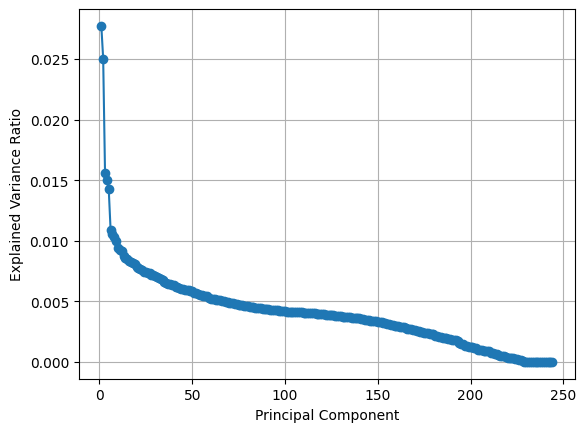

In [ ]:
#This part simply shows how much variance each principal component captures


#this shows that pca actually wont be much of a help in this case since there is not single pca that dominates by 60 or 70% of the vaiance.
#as shown below, the first 182 pcas can reach up to 95% of the variance. Yeah since we have 244 features, they got reducted to 182 so its still a reduction but not a huge one
# So what can be noted is ===> structure is spread across many dimensions and there is no single direction that explains most of the variance

#so like the first pca =~2.8% variance and it gradually decreases so there is no sharp drop after the first few pcas

pca = PCA().fit(X_train_enco)

plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         pca.explained_variance_ratio_, marker='o')
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.show()

In [ ]:
# Applying PCA function on training and testing set of X component while preserving 95% of the variance

pca_1 = PCA(n_components=0.95)

X_train_reduced = pca_1.fit_transform(X_train_enco)
X_test_reduced = pca_1.transform(X_test_enco)

explained_variance = pca_1.explained_variance_ratio_

In [ ]:
len(X_train_reduced[0]) #number of PCAs kept

182

In [ ]:

# when K=3, the silhouette score slightly improved (after pca : ~0.108, before pca: ~0.095). thus it slightly improved the geometric separation.
# The adjusted random index was much lower (before: ~0.154, after: ~0.054). so the alignment with true labels was much worse
# Pca improved slightly the geometric separation but resulted in a much worse alignment with true labels
# The structure of the clusters showed a tiny cluster with one data point
#so for k=3 (after PCA): pca didnt improve meaningful clustering

kmeans_pca2 = KMeans(n_clusters=3, random_state=42)
clusters_pca2 = kmeans_pca2.fit_predict(X_train_reduced)

# Silhouette
s_score_pca2 = silhouette_score(X_train_reduced, clusters_pca2)
print("PCA (k=3) Silhouette:", s_score_pca2)

# ARI
ari_pca2 = adjusted_rand_score(y_train, clusters_pca2)
print("PCA (k=3) ARI:", ari_pca2 )

# Cross_tabulation
clust_dist_pca2 = pd.crosstab(clusters_pca2, y_train)
print("\nPCA (k=3) Crosstab:")
print(clust_dist_pca2)

PCA (k=3) Silhouette: 0.10784119211040505
PCA (k=3) ARI: 0.05449226771577917

PCA (k=3) Crosstab:
Target     0    1    2
row_0                 
0       1374  600  475
1        393  536  160
2          0    1    0


#### 3D PCA plot

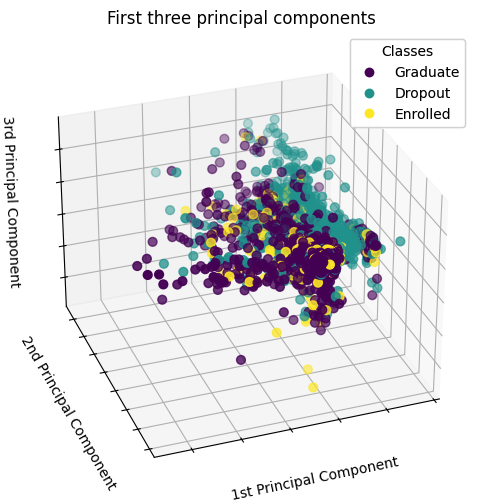

In [ ]:
#shows the original encoded data projected onto the first 3 pcas.

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

scatter = ax.scatter(
    X_train_reduced[:, 0],
    X_train_reduced[:, 1],
    X_train_reduced[:, 2],
    c=y_train,
    s=40,
)

ax.set(
    title="First three principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component",
    zlabel="3rd Principal Component",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# Add a legend
legend1 = ax.legend(
    scatter.legend_elements()[0],
    ['Graduate', 'Dropout', 'Enrolled'],
    loc="upper right",
    title="Classes",
)
ax.add_artist(legend1)

plt.show()

#**My conclusion:**

##**PCA was not helpful**
-It improved the silhouette but the ARI became much worse

-so it improved geometric separation but destroyes class structure

###**This might happened bcz:**

*   pca keeps features with high variance so might be that some of the features that distinguishes the classes had low variance so pca reduced their importance and as a result they were removed



### **other thing to mention:**  
-there is no need to balance the data for k-means since balancing methods are designed for classification problems not clustering (bcz clustering doesnt use labels, while balancing uses labels to modify the dataset). Long story short, we shouldnt balance the data here, cuz the problem is to minime the within-cluster variance not to create equally sized groups !!





#